<a href="https://colab.research.google.com/github/omkargend455/doc-extract-ai/blob/main/notebooks/sroie_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os

base = "/content/drive/MyDrive/sroie"

print("Folder exists:", os.path.exists(base))
print("Contents:", os.listdir(base) if os.path.exists(base) else "Not found")

Folder exists: True
Contents: ['0325updated.task2train(626p) (1)', '0325updated.task1train(626p) (1)']


In [4]:
import os

base = "/content/drive/MyDrive/sroie"
task2 = os.path.join(base, "0325updated.task2train(626p) (1)")

print("Folder exists:", os.path.exists(task2))
print("Number of items:", len(os.listdir(task2)))

# Preview first 10 files
for name in os.listdir(task2)[:10]:
    print(name)

Folder exists: True
Number of items: 1611
X51005757294 (1).jpg
X51005757324 (1).jpg
X51005757346 (1).jpg
X51005806679 (2).txt
X51005806698 (2).txt
X51005806685 (2).txt
X51005806703 (2).txt
X51005806702 (2).txt
X51005806702 (1).jpg
X51005806716 (1).jpg


In [5]:
from pathlib import Path

files = list(Path(task2).iterdir())

images = {p.stem for p in files if p.suffix.lower() in {".jpg", ".jpeg", ".png"}}
labels = {p.stem for p in files if p.suffix.lower() == ".txt"}

print("Images:", len(images))
print("Annotations:", len(labels))
print("Matched pairs:", len(images & labels))
print("Images without annotations:", len(images - labels))
print("Annotations without images:", len(labels - images))

Images: 735
Annotations: 876
Matched pairs: 727
Images without annotations: 8
Annotations without images: 149


In [6]:
from pathlib import Path
from collections import Counter
import json

root = Path(task2)
files = list(root.iterdir())

print("File extensions:", Counter(p.suffix.lower() for p in files))

print("\nSample images:")
for p in sorted(root.glob("*.jpg"))[:15]:
    print(p.name)

print("\nSample annotation contents:")
for p in sorted(root.glob("*.txt"))[:3]:
    print(f"\n--- {p.name} ---")
    try:
        print(json.dumps(json.loads(p.read_text(encoding="utf-8")), indent=2))
    except Exception as e:
        print("Could not parse as JSON:", e)
        print(p.read_text(encoding="utf-8", errors="replace")[:500])

File extensions: Counter({'.txt': 876, '.jpg': 735})

Sample images:
X00016469612.jpg
X00016469619.jpg
X00016469620.jpg
X00016469622.jpg
X00016469623.jpg
X00016469669.jpg
X00016469672.jpg
X00016469676.jpg
X51005200938.jpg
X51005230617.jpg
X51005255805.jpg
X51005268200.jpg
X51005268262.jpg
X51005268400.jpg
X51005268472.jpg

Sample annotation contents:

--- X00016469612.txt ---
{
  "company": "BOOK TA .K (TAMAN DAYA) SDN BHD",
  "date": "25/12/2018",
  "address": "NO.53 55,57 & 59, JALAN SAGU 18, TAMAN DAYA, 81100 JOHOR BAHRU, JOHOR.",
  "total": "9.00"
}

--- X00016469619.txt ---
{
  "company": "INDAH GIFT & HOME DECO",
  "date": "19/10/2018",
  "address": "27, JALAN DEDAP 13, TAMAN JOHOR JAYA, 81100 JOHOR BAHRU, JOHOR.",
  "total": "60.30"
}

--- X00016469620.txt ---
{
  "company": "MR D.I.Y. (JOHOR) SDN BHD",
  "date": "12-01-19",
  "address": "LOT 1851-A & 1851-B, JALAN KPB 6, KAWASAN PERINDUSTRIAN BALAKONG, 43300 SERI KEMBANGAN, SELANGOR (MR DIY TESCO TERBAU)",
  "total": "33.90"
}


In [7]:
import re
from collections import defaultdict

def normalized_stem(name):
    # Remove a trailing copy suffix such as " (1)" or " (2)"
    return re.sub(r" \(\d+\)$", "", Path(name).stem)

images_by_id = defaultdict(list)
labels_by_id = defaultdict(list)

for p in files:
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
        images_by_id[normalized_stem(p.name)].append(p.name)
    elif p.suffix.lower() == ".txt":
        labels_by_id[normalized_stem(p.name)].append(p.name)

image_ids = set(images_by_id)
label_ids = set(labels_by_id)

print("Matched after suffix normalization:", len(image_ids & label_ids))
print("Images still unmatched:", len(image_ids - label_ids))
print("Annotations still unmatched:", len(label_ids - image_ids))

print("\nExample duplicate image IDs:")
for key, names in images_by_id.items():
    if len(names) > 1:
        print(key, "->", names[:5])

Matched after suffix normalization: 626
Images still unmatched: 0
Annotations still unmatched: 0

Example duplicate image IDs:
X51005757294 -> ['X51005757294 (1).jpg', 'X51005757294.jpg']
X51005757324 -> ['X51005757324 (1).jpg', 'X51005757324.jpg']
X51005757346 -> ['X51005757346 (1).jpg', 'X51005757346.jpg']
X51005806702 -> ['X51005806702 (1).jpg', 'X51005806702.jpg']
X51005806716 -> ['X51005806716 (1).jpg', 'X51005806716.jpg']
X51005757349 -> ['X51005757349 (2).jpg', 'X51005757349 (1).jpg', 'X51005757349.jpg']
X51005763940 -> ['X51005763940 (2).jpg', 'X51005763940 (1).jpg', 'X51005763940.jpg']
X51005757351 -> ['X51005757351 (2).jpg', 'X51005757351 (1).jpg', 'X51005757351.jpg']
X51005757353 -> ['X51005757353 (2).jpg', 'X51005757353 (1).jpg', 'X51005757353.jpg']
X51005757304 -> ['X51005757304.jpg', 'X51005757304 (1).jpg']
X51005757323 -> ['X51005757323.jpg', 'X51005757323 (1).jpg']
X51006311779 -> ['X51006311779 (1).jpg', 'X51006311779.jpg']
X51006311767 -> ['X51006311767 (1).jpg', 'X51

In [8]:
from pathlib import Path
from collections import defaultdict
import json
import re

root = Path(task2)

def original_id(filename):
    return re.sub(r" \(\d+\)$", "", Path(filename).stem)

images_by_id = defaultdict(list)
labels_by_id = defaultdict(list)

for p in root.iterdir():
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
        images_by_id[original_id(p.name)].append(p)
    elif p.suffix.lower() == ".txt":
        labels_by_id[original_id(p.name)].append(p)

# Only IDs with exactly one image and exactly one annotation
clean_ids = sorted(
    image_id
    for image_id in set(images_by_id) & set(labels_by_id)
    if len(images_by_id[image_id]) == 1
    and len(labels_by_id[image_id]) == 1
)

records = []

for image_id in clean_ids:
    image_path = images_by_id[image_id][0]
    label_path = labels_by_id[image_id][0]

    try:
        label = json.loads(label_path.read_text(encoding="utf-8"))
        required = {"company", "date", "address", "total"}

        if not required.issubset(label):
            continue

        records.append({
            "id": image_id,
            "image_path": str(image_path),
            "label_path": str(label_path),
            "ground_truth": label
        })
    except (json.JSONDecodeError, OSError):
        continue

print("Unique, unambiguous image-label pairs:", len(records))
print("Example record:")
print(json.dumps(records[0], indent=2, ensure_ascii=False) if records else "No valid records")

Unique, unambiguous image-label pairs: 437
Example record:
{
  "id": "X00016469612",
  "image_path": "/content/drive/MyDrive/sroie/0325updated.task2train(626p) (1)/X00016469612.jpg",
  "label_path": "/content/drive/MyDrive/sroie/0325updated.task2train(626p) (1)/X00016469612.txt",
  "ground_truth": {
    "company": "BOOK TA .K (TAMAN DAYA) SDN BHD",
    "date": "25/12/2018",
    "address": "NO.53 55,57 & 59, JALAN SAGU 18, TAMAN DAYA, 81100 JOHOR BAHRU, JOHOR.",
    "total": "9.00"
  }
}


In [9]:
from sklearn.model_selection import train_test_split
import pandas as pd

train_records, test_records = train_test_split(
    records,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("Development records:", len(train_records))
print("Held-out records:", len(test_records))

# Save the split manifest to Google Drive (not the receipt images)
manifest_dir = "/content/drive/MyDrive/doc-extract-ai/manifests"
import os, json
os.makedirs(manifest_dir, exist_ok=True)

def manifest_rows(items, split):
    return [
        {
            "id": r["id"],
            "image_path": r["image_path"],
            "label_path": r["label_path"],
            "split": split
        }
        for r in items
    ]

manifest = (
    manifest_rows(train_records, "development")
    + manifest_rows(test_records, "held_out")
)

manifest_path = os.path.join(manifest_dir, "sroie_split_seed42.json")
with open(manifest_path, "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

print("Saved split manifest:", manifest_path)

Development records: 349
Held-out records: 88
Saved split manifest: /content/drive/MyDrive/doc-extract-ai/manifests/sroie_split_seed42.json


In [10]:
!apt-get -qq update
!apt-get -qq install -y tesseract-ocr
!pip -q install pytesseract pillow pandas rapidfuzz

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 53.9 MB/s eta 0:00:00


In [11]:
import pytesseract
from PIL import Image
import pandas as pd
import rapidfuzz

print("Tesseract version:", pytesseract.get_tesseract_version())
print("OCR dependencies installed successfully.")

Tesseract version: 5.3.4
OCR dependencies installed successfully.


In [12]:
sample = train_records[0]

image = Image.open(sample["image_path"]).convert("RGB")
ocr_text = pytesseract.image_to_string(image)

print("Receipt ID:", sample["id"])
print("\n--- OCR TEXT ---\n")
print(ocr_text)

Receipt ID: X51006619862

--- OCR TEXT ---




In [13]:
print("Receipt ID:", sample["id"])
print("Image size:", image.size)
print("OCR character count:", len(ocr_text))
print("\nFull OCR output:\n")
print(repr(ocr_text))

Receipt ID: X51006619862
Image size: (884, 1833)
OCR character count: 0

Full OCR output:

''


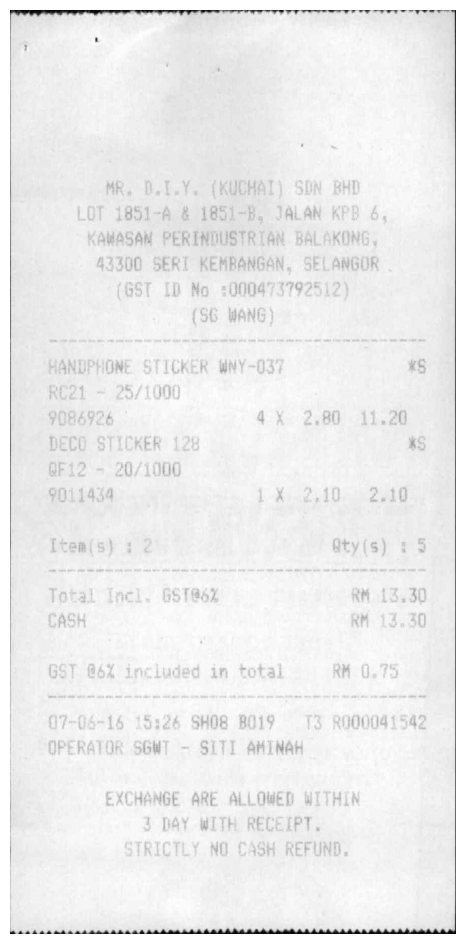

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 12))
plt.imshow(image)
plt.axis("off")
plt.show()

In [15]:
for psm in [3, 4, 6, 11]:
    config = f"--oem 3 --psm {psm}"
    text = pytesseract.image_to_string(image, config=config)

    print(f"\n--- PSM {psm}: {len(text)} characters ---")
    print(text[:1500] if text.strip() else "[No text detected]")



--- PSM 3: 0 characters ---
[No text detected]

--- PSM 4: 0 characters ---
[No text detected]

--- PSM 6: 3 characters ---
Se


--- PSM 11: 82 characters ---
ee ae ee ee SL le eee

‘a iti

Pe ere ee ee eee eee eT OU OO OUT YT OUT TTC UT UT



In [16]:
print(pytesseract.get_languages(config=""))
print("Image mode:", image.mode)
print("Image dimensions:", image.size)

['eng', 'osd']
Image mode: RGB
Image dimensions: (884, 1833)


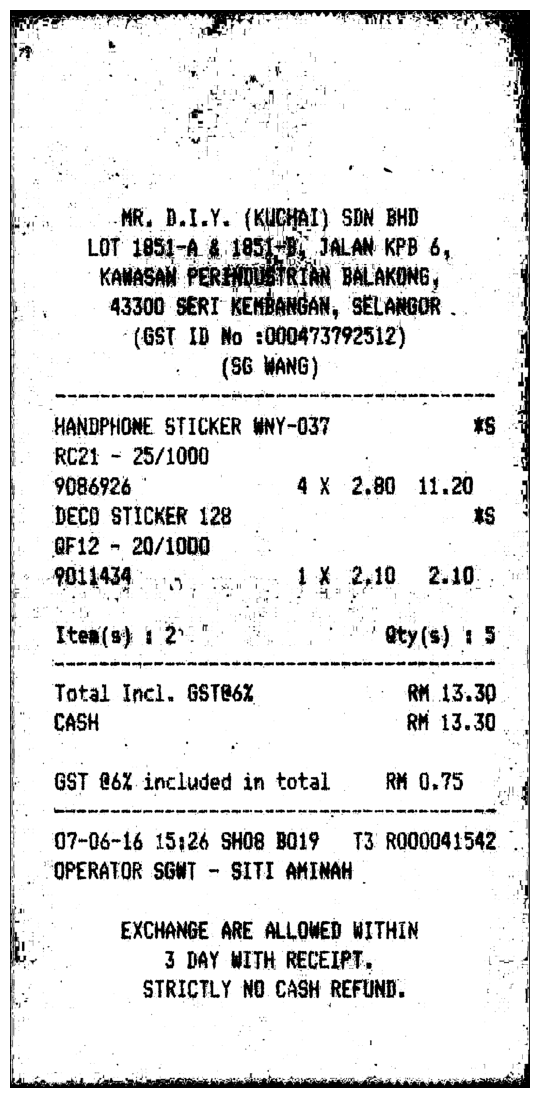

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Convert the receipt to grayscale
gray = cv2.cvtColor(np.array(image), cv2.COLOR_RGB2GRAY)

# Enlarge the image for OCR
gray = cv2.resize(
    gray, None, fx=2, fy=2,
    interpolation=cv2.INTER_CUBIC
)

# Improve local contrast
clahe = cv2.createCLAHE(
    clipLimit=3.0,
    tileGridSize=(8, 8)
)
enhanced = clahe.apply(gray)

# Sharpen the text
blurred = cv2.GaussianBlur(enhanced, (0, 0), 2)
sharpened = cv2.addWeighted(enhanced, 1.8, blurred, -0.8, 0)

# Create a black-and-white version
binary = cv2.threshold(
    sharpened, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)[1]

plt.figure(figsize=(10, 14))
plt.imshow(binary, cmap="gray")
plt.axis("off")
plt.show()

In [18]:
for psm in [3, 4, 6, 11]:
    text = pytesseract.image_to_string(
        binary,
        config=f"--oem 3 --psm {psm}"
    )

    print(f"\n--- PSM {psm}: {len(text.strip())} characters ---")
    print(text[:2000] if text.strip() else "[No text detected]")


--- PSM 3: 772 characters ---
Me DALY (Kuck) SIN BHD
$188 2 JALAN KPB 6,
ail PER; HUUBTRIAN BALAKONG,
43300 SERT- RENN, ‘SELANGOR .
“(GST ID No 1000473792512)
| (86 Wane)

| HANDPHONE STICKER WnY-037

RC2t - 28/1000 . :
9086926 AX 2,80 11.20
DECO STICKER 128 OO
| 8F12 = 20/1000
Er POLAT oi AE, 2 10 2.10.

i Ttea(s) t > ee | * @ty(s) 1 5

et) og om ew ann 00 nd am en dt OR MG at Ub ome ote Ae ub bine 0D Ae are eat ime Ok aoe woe ous ait -

Total Incl. GSTR6X = RM ATL
CASH : RH 13.30,

“ast Qbx. included i in total —-RM 0.75

. ra
. fem cacy wm ne re stn ene es pom fe a Oe mE, HOY ONE OID OS LA OD Re Lees SO OR 9 Re oe HOE NO OEE RS. Rew Om seo YY, 4
’

7-06-16 15426 SHOR BOLTS ROOODALSAZ ~
| OPERATOR SGHT - SITI AMINAH

EXCHANGE ARE ALLOWED WITHIN
3 DAY WITH RECEIPT,
STRICTLY NO. CASH REFUND.



--- PSM 4: 588 characters ---
WR. DALY. (Kuck) SIN BHD
“uot 1851-4. 8.105; 2 JALAN KPB 6,
A PEREAULETRIAN: BALAKONG,
43300 SERT- RENN, ‘SELANGOR .
“(GST ID No 1000473792512)
| (86 Wane)

| HAND

In [19]:
import re
import json

def extract_receipt_fields(ocr_text):
    lines = [
        line.strip()
        for line in ocr_text.splitlines()
        if line.strip()
    ]

    # Preserve OCR text as-is; return candidates, not assumed truths.
    date_pattern = re.compile(
        r"\b\d{1,2}[-/]\d{1,2}[-/]\d{2,4}\b"
    )
    money_pattern = re.compile(
        r"\b(?:RM\s*)?\d{1,6}\.\d{2}\b",
        re.IGNORECASE
    )

    dates = [
        match.group(0)
        for line in lines
        for match in date_pattern.finditer(line)
    ]

    amounts = [
        match.group(0)
        for line in lines
        for match in money_pattern.finditer(line)
    ]

    # Heuristic candidates only; these need validation.
    company_candidate = lines[0] if lines else None

    total_candidates = [
        line for line in lines
        if re.search(r"\b(total|cash|amount)\b", line, re.I)
    ]

    address_candidates = [
        line for line in lines
        if re.search(
            r"\b(lot|jalan|street|road|selangor|address|balakong)\b",
            line,
            re.I
        )
    ]

    return {
        "company_candidate": company_candidate,
        "date_candidates": dates,
        "address_candidates": address_candidates,
        "total_line_candidates": total_candidates,
        "amount_candidates": amounts,
    }

candidates = extract_receipt_fields(ocr_text)

print(json.dumps(candidates, indent=2))

{
  "company_candidate": null,
  "date_candidates": [],
  "address_candidates": [],
  "total_line_candidates": [],
  "amount_candidates": []
}


In [20]:
print("Receipt ID:", sample["id"])

with open(sample["label_path"], "r", encoding="utf-8") as f:
    ground_truth = json.load(f)

print(json.dumps(ground_truth, indent=2, ensure_ascii=False))

Receipt ID: X51006619862
{
  "company": "MR. D.I.Y. (KUCHAI) SDN BHD",
  "date": "07-06-16",
  "address": "LOT 1851-A & 1851-B, JALAN KPB 6, KAWASAN PERINDUSTRIAN BALAKONG, 43300 SERI KEMBANGAN, SELANGOR",
  "total": "RM 13.30"
}
